# Linear relationships, Ridge and Lasso

**Question:** is there a linear relationship between the audio features of current hit songs and their popularity? And which variables survive once the regression is regularized with **Ridge** (L2) and **Lasso** (L1)?

**Data:** `data/spotify_top200_songs_20261012.csv`. This is one row per unique song from the Spotify daily Top 200 of 12 countries (842 songs), generated by `get_current_data.py`.

**Steps**
1. Linear relationship of each feature with popularity (correlations and scatter plots).
2. Linear relationships *between* the features (correlation matrix and VIF), i.e. multicollinearity.
3. OLS baseline and residual check.
4. Ridge and Lasso with the penalty `alpha` chosen by cross-validation, and their coefficient paths.
5. Comparison of OLS, Ridge and Lasso coefficients and predictive performance.
6. The same models controlling for market reach (US chart, number of countries).
7. Conclusions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Colors (validated categorical palette: blue, orange, aqua) and recessive ink
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, INK, INK_2 = "#c3c2b7", "#0b0b0b", "#52514e"
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2, "xtick.color": INK_2,
    "ytick.color": INK_2, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "lines.linewidth": 2,
})
RANDOM_STATE = 42

## 1. Data

- **y = `log_streams`**, the log of daily streams summed across the countries where the song charts. Streams are heavily right-skewed, and the log makes the relationship closer to linear and the residuals closer to normal.
- **X = audio features.** `key` (pitch class 0-11) is left out because it is categorical with no linear order. `mode` is binary (major = 1).

In [2]:
DATA_PATH = "data/spotify_top200_songs_20261012.csv"
FEATURES = [
    "danceability", "energy", "valence", "acousticness", "instrumentalness",
    "speechiness", "liveness", "loudness", "tempo", "mode",
]

df = pd.read_csv(DATA_PATH)
df["log_streams"] = np.log(df["daily_streams"])
X, y = df[FEATURES], df["log_streams"]

print(f"{len(df)} songs, {len(FEATURES)} features, missing values: {df[FEATURES].isna().sum().sum()}")
df[FEATURES + ["daily_streams", "log_streams"]].describe().T.round(3)

842 songs, 10 features, missing values: 0


,count,mean,std,min,25%,50%,75%,max
danceability,842.0,0.642,0.140,0.142,0.548,0.661,0.746,0.959
energy,842.0,0.681,0.157,0.003,0.590,0.696,0.796,0.998
valence,842.0,0.558,0.231,0.000,0.380,0.556,0.752,0.981
acousticness,842.0,0.256,0.226,0.000,0.065,0.190,0.394,0.968
instrumentalness,842.0,0.016,0.096,0.000,0.000,0.000,0.000,0.995
speechiness,842.0,0.084,0.083,0.024,0.035,0.048,0.092,0.513
liveness,842.0,0.190,0.165,0.023,0.098,0.129,0.217,0.973
loudness,842.0,-6.552,3.221,-46.113,-7.505,-6.091,-4.832,-0.766
tempo,842.0,123.519,28.889,48.718,99.994,120.970,140.036,205.850
mode,842.0,0.548,0.498,0.000,0.000,1.000,1.000,1.000


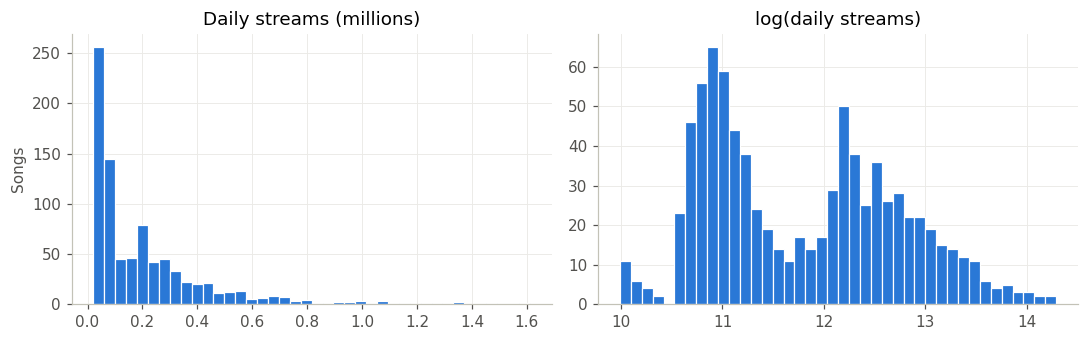

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df["daily_streams"] / 1e6, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
axes[0].set(title="Daily streams (millions)", ylabel="Songs")
axes[1].hist(y, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
axes[1].set(title="log(daily streams)")
plt.tight_layout()

## 2. Linear relationship of each feature with popularity

Pearson's *r* measures **linear** association. Spearman's ρ measures monotonic association. If ρ is much larger than *r*, the relationship exists but is not linear.

In [4]:
corr = pd.DataFrame({
    "pearson_r": X.corrwith(y),
    "spearman_rho": X.corrwith(y, method="spearman"),
})
corr["pearson_p"] = [sm.OLS(y, sm.add_constant(X[f])).fit().pvalues[f] for f in FEATURES]
corr.sort_values("pearson_r", key=abs, ascending=False).round(3)

,pearson_r,spearman_rho,pearson_p
speechiness,-0.186,-0.138,0.000
energy,-0.107,-0.094,0.002
acousticness,0.099,0.089,0.004
liveness,0.067,0.018,0.054
loudness,-0.057,-0.019,0.099
instrumentalness,0.045,0.084,0.196
mode,0.043,0.045,0.214
danceability,-0.037,0.002,0.288
tempo,-0.023,-0.031,0.502
valence,-0.003,0.009,0.928


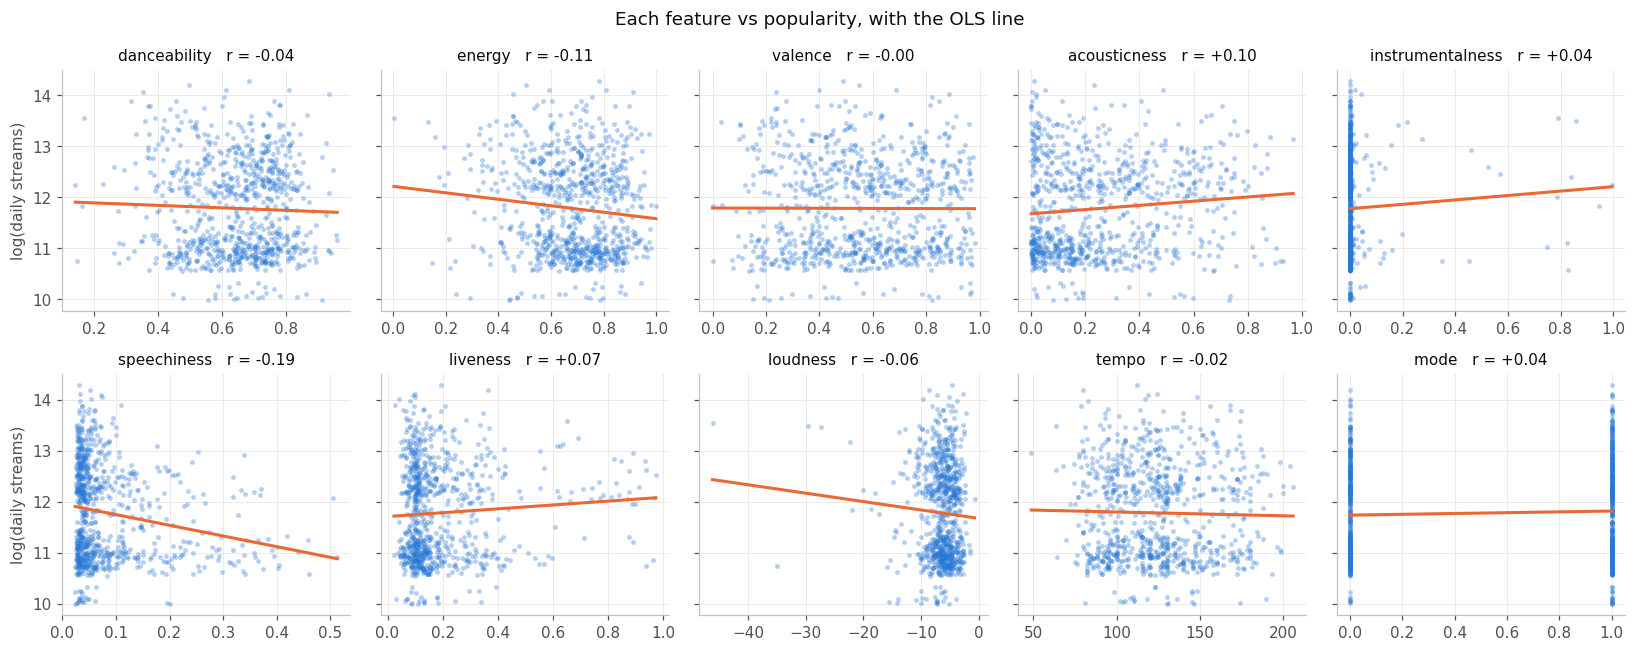

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharey=True)
for ax, f in zip(axes.flat, FEATURES):
    ax.scatter(X[f], y, s=10, alpha=0.35, color=BLUE, linewidths=0)
    slope, intercept = np.polyfit(X[f], y, 1)
    xs = np.linspace(X[f].min(), X[f].max(), 100)
    ax.plot(xs, intercept + slope * xs, color=ORANGE)
    ax.set_title(f"{f}   r = {corr.loc[f, 'pearson_r']:+.2f}", fontsize=10, color=INK)
for ax in axes[:, 0]:
    ax.set_ylabel("log(daily streams)")
fig.suptitle("Each feature vs popularity, with the OLS line", color=INK)
plt.tight_layout()

## 3. Linear relationships between the features (multicollinearity)

Ridge and Lasso matter most when the predictors are correlated with each other. There are two checks:
- **Correlation matrix**: |r| > 0.7 between two features is a warning sign.
- **VIF** (variance inflation factor): VIF > 5 means moderate multicollinearity, and VIF > 10 means severe.

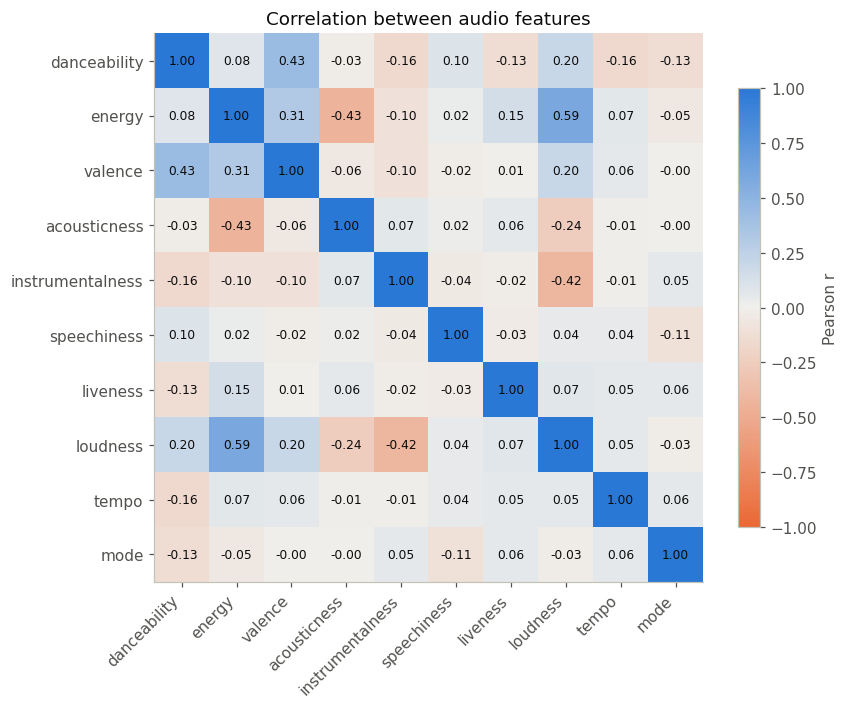

In [6]:
fig, ax = plt.subplots(figsize=(8, 6.5))
cm = X.corr()
im = ax.imshow(cm, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.grid(False)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation between audio features", color=INK)
plt.tight_layout()

In [7]:
X_const = sm.add_constant(X)
vif = pd.Series(
    [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
    index=FEATURES, name="VIF",
).sort_values(ascending=False)
vif.round(2).to_frame()

,VIF
energy,2.11
loudness,1.98
valence,1.42
danceability,1.41
instrumentalness,1.28
acousticness,1.27
liveness,1.07
tempo,1.06
mode,1.04
speechiness,1.03


## 4. OLS baseline

The plain multiple linear regression is the reference point. The **F-test** checks whether the features *jointly* have a linear relationship with popularity.

In [8]:
ols = sm.OLS(y, X_const).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:            log_streams   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                  0.046
Method:                 Least Squares   F-statistic:                     5.012
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           4.25e-07
Time:                        17:05:26   Log-Likelihood:                -1114.1
No. Observations:                 842   AIC:                             2250.
Df Residuals:                     831   BIC:                             2302.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               12.4311      0.362  

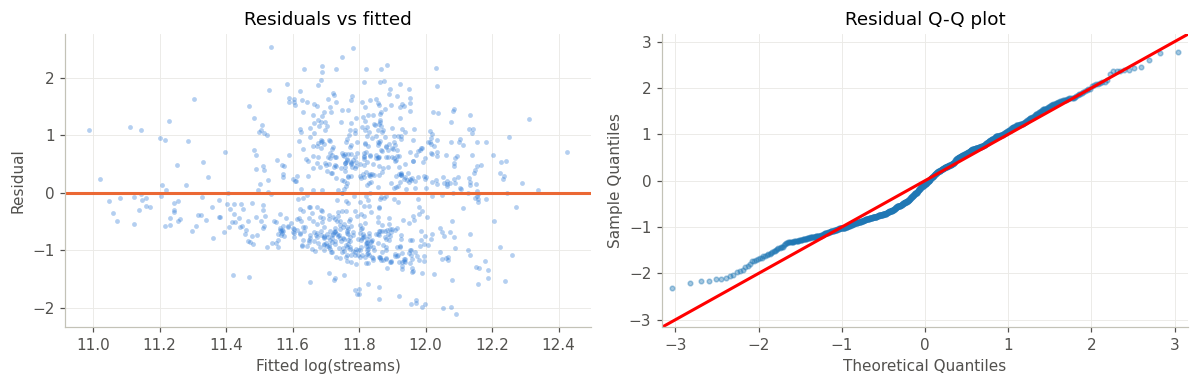

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(ols.fittedvalues, ols.resid, s=10, alpha=0.35, color=BLUE, linewidths=0)
axes[0].axhline(0, color=ORANGE)
axes[0].set(title="Residuals vs fitted", xlabel="Fitted log(streams)", ylabel="Residual")
sm.qqplot(ols.resid, line="45", fit=True, ax=axes[1], markersize=3, alpha=0.4)
axes[1].set_title("Residual Q-Q plot")
plt.tight_layout()

## 5. Ridge and Lasso

Both models add a penalty on the size of the coefficients:

- **Ridge (L2):** minimizes RSS + α·Σβ². It shrinks all coefficients towards 0 but never makes them exactly 0. It is useful when predictors are correlated.
- **Lasso (L1):** minimizes RSS + α·Σ|β|. It can set coefficients **exactly to 0**, so it also does **variable selection**.

The features are **standardized** first, so the penalty treats them all equally and the coefficients are comparable: each one is the change in log(streams) for a 1 standard deviation increase in the feature. `alpha` is chosen by 5-fold cross-validation.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ridge_alphas = np.logspace(-2, 5, 200)

models = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alphas)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=cv, alphas=200, random_state=RANDOM_STATE, max_iter=50_000)),
}
for m in models.values():
    m.fit(X, y)

alpha_ridge = models["Ridge"][-1].alpha_
alpha_lasso = models["Lasso"][-1].alpha_
print(f"Best Ridge alpha: {alpha_ridge:.2f}")
print(f"Best Lasso alpha: {alpha_lasso:.4f}")

Best Ridge alpha: 230.04
Best Lasso alpha: 0.0159


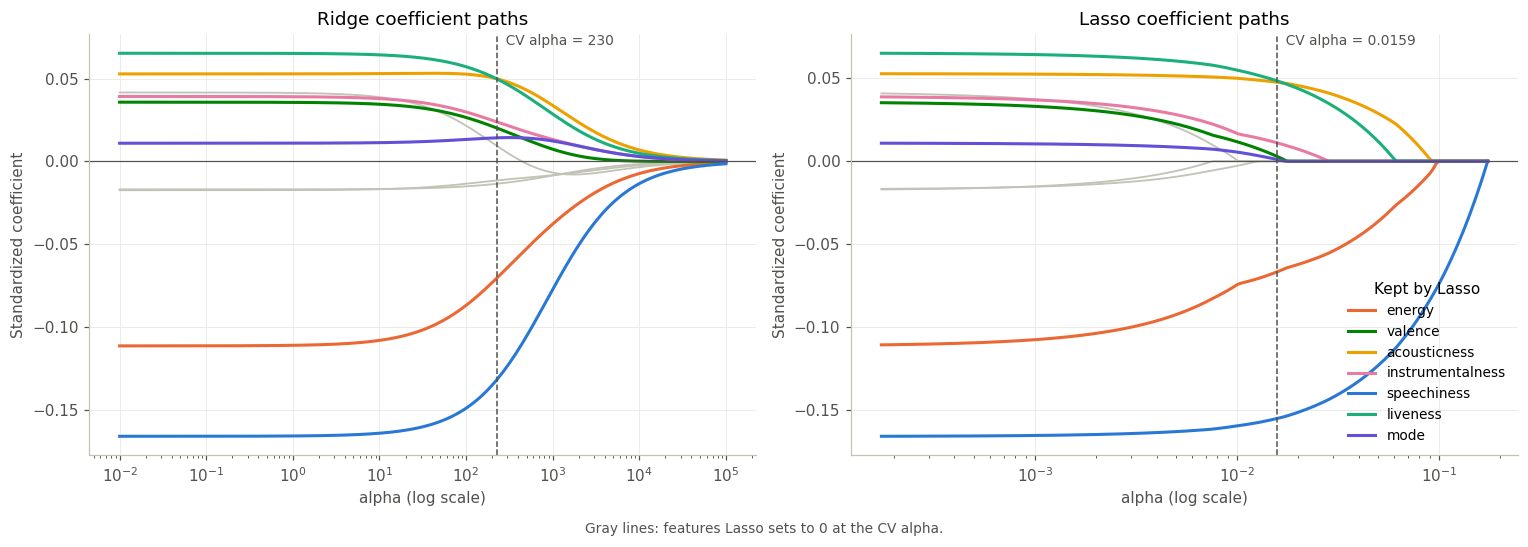

In [11]:
X_std = StandardScaler().fit_transform(X)
lasso_alphas = models["Lasso"][-1].alphas_

ridge_path = np.array([Ridge(alpha=a).fit(X_std, y).coef_ for a in ridge_alphas])
lasso_path = np.array([Lasso(alpha=a, max_iter=50_000).fit(X_std, y).coef_ for a in lasso_alphas])

# Highlight the features Lasso keeps at the best alpha; the rest stay gray.
lasso_coef = pd.Series(models["Lasso"][-1].coef_, index=FEATURES)
kept = lasso_coef[lasso_coef.abs() > 1e-4].abs().sort_values(ascending=False).index.tolist()
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
color_of = {f: SERIES[i] for i, f in enumerate(kept[:len(SERIES)])}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, path, alphas, best, name in [
    (axes[0], ridge_path, ridge_alphas, alpha_ridge, "Ridge"),
    (axes[1], lasso_path, lasso_alphas, alpha_lasso, "Lasso"),
]:
    for j, f in enumerate(FEATURES):
        if f not in color_of:
            ax.plot(alphas, path[:, j], color=GRAY, linewidth=1.2, zorder=1)
    for j, f in enumerate(FEATURES):
        if f in color_of:
            ax.plot(alphas, path[:, j], color=color_of[f], label=f, zorder=2)
    ax.axvline(best, color=INK_2, linestyle="--", linewidth=1)
    ax.text(best, ax.get_ylim()[1], f"  CV alpha = {best:.3g}", color=INK_2, va="top", fontsize=9)
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set(xscale="log", xlabel="alpha (log scale)", ylabel="Standardized coefficient",
           title=f"{name} coefficient paths")
axes[1].legend(title="Kept by Lasso", frameon=False, fontsize=9, loc="lower right")
fig.text(0.5, -0.02, "Gray lines: features Lasso sets to 0 at the CV alpha.", ha="center", color=INK_2, fontsize=9)
plt.tight_layout()

## 6. Comparing OLS, Ridge and Lasso

In [ ]:
coefs = pd.DataFrame({name: m[-1].coef_ for name, m in models.items()}, index=FEATURES)
coefs["OLS p-value"] = ols.pvalues[FEATURES]
coefs["Lasso keeps it"] = coefs["Lasso"].abs() > 1e-4
coefs = coefs.reindex(coefs["OLS"].abs().sort_values(ascending=False).index)
coefs.round(4)

,OLS,Ridge,Lasso,OLS p-value,Lasso keeps it
speechiness,-0.1662,-0.1316,-0.1553,0.0000,True
energy,-0.1115,-0.0702,-0.0667,0.0151,True
liveness,0.0653,0.0497,0.0484,0.0454,True
acousticness,0.0529,0.0498,0.0477,0.1375,True
loudness,0.0417,0.0091,0.0000,0.3475,False
instrumentalness,0.0392,0.0237,0.0110,0.2718,True
valence,0.0358,0.0200,0.0028,0.3402,True
danceability,-0.0174,-0.0115,-0.0000,0.6411,False
tempo,-0.0169,-0.0135,-0.0000,0.6021,False
mode,0.0110,0.0142,0.0010,0.7334,True


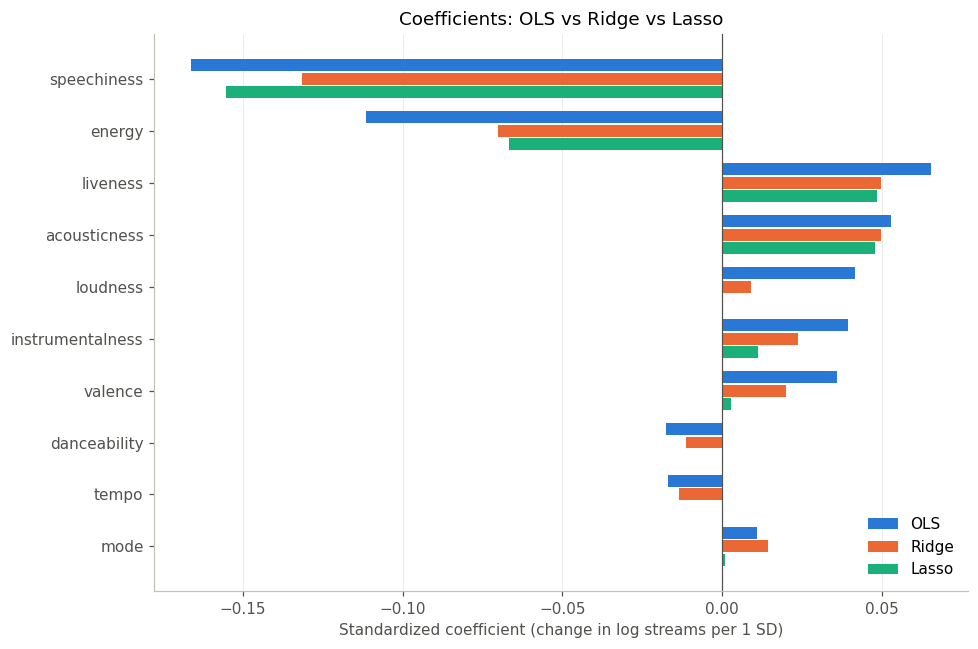

In [ ]:
order = coefs.index[::-1]
h = 0.26
yy = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 6))
for k, (name, color) in enumerate([("OLS", BLUE), ("Ridge", ORANGE), ("Lasso", AQUA)]):
    ax.barh(yy + (1 - k) * h, coefs.loc[order, name], height=h - 0.03, color=color, label=name)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_yticks(yy, order)
ax.set(xlabel="Standardized coefficient (change in log streams per 1 SD)",
       title="Coefficients: OLS vs Ridge vs Lasso")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()

**Predictive performance.** In-sample R² always favors OLS. The fair comparison is the **cross-validated R²** on held-out folds.

In [ ]:
perf = pd.DataFrame({
    name: {
        "R2 (in-sample)": m.score(X, y),
        "R2 (5-fold CV)": cross_val_score(m, X, y, cv=cv, scoring="r2").mean(),
        "RMSE (5-fold CV)": -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean(),
        "non-zero coefs": int((np.abs(m[-1].coef_) > 1e-4).sum()),
    }
    for name, m in models.items()
}).T
perf.round(4)

,R2 (in-sample),R2 (5-fold CV),RMSE (5-fold CV),non-zero coefs
OLS,0.0569,0.0341,0.9169,10.0
Ridge,0.0539,0.0341,0.9169,10.0
Lasso,0.0536,0.0322,0.9178,7.0


## 7. Controlling for market reach

The scatter plots show that log(streams) has **two clusters**, one around 11 and another around 12.5-13. This is not about the audio. Our popularity measure sums the streams of every country where a song charts, so it depends heavily on **where** the song charts:
- A song in the US Top 200 gets far more streams than a song that only charts in, say, the Netherlands.
- A song that charts in 8 countries adds up 8 sets of streams.

If some audio features are more common in big markets, their coefficients mix "sounds like X" with "is a US/global hit". To separate the two, we add two **reach controls**:
- `in_us`: 1 if the song is in the US Top 200, the largest market.
- `log_n_countries`: log of the number of countries where the song charts.

       count   mean   std
in_us                    
0        693  11.50  0.76
1        149  13.09  0.45

corr(log_streams, log_n_countries) = 0.663


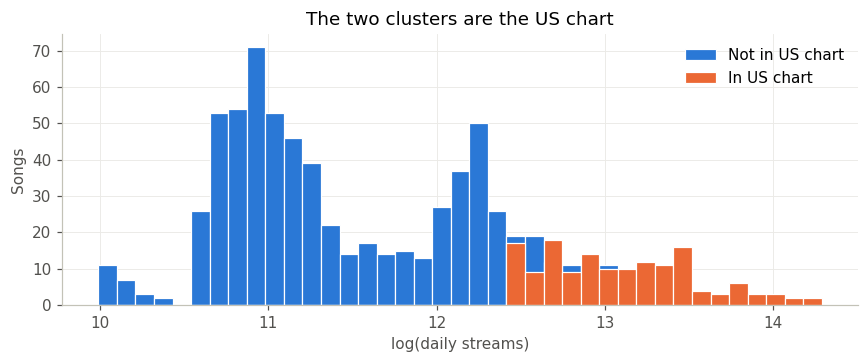

In [15]:
countries = pd.read_csv(DATA_PATH.replace("_songs_", "_countries_"))
us_ids = set(countries.loc[countries["country_code"] == "us", "track_id"])
df["in_us"] = df["track_id"].isin(us_ids).astype(int)
df["log_n_countries"] = np.log(df["n_countries"])
CONTROLS = ["in_us", "log_n_countries"]

print(df.groupby("in_us")["log_streams"].agg(["count", "mean", "std"]).round(2))
print(f"\ncorr(log_streams, log_n_countries) = {df['log_streams'].corr(df['log_n_countries']):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(y.min(), y.max(), 40)
ax.hist(y[df["in_us"] == 0], bins=bins, color=BLUE, edgecolor="white", linewidth=0.8, label="Not in US chart")
ax.hist(y[df["in_us"] == 1], bins=bins, color=ORANGE, edgecolor="white", linewidth=0.8, label="In US chart")
ax.set(xlabel="log(daily streams)", ylabel="Songs", title="The two clusters are the US chart")
ax.legend(frameon=False)
plt.tight_layout()

In [16]:
X_ctrl = df[FEATURES + CONTROLS]

ols_ctrl = sm.OLS(y, sm.add_constant(X_ctrl)).fit()
ols_reach = sm.OLS(y, sm.add_constant(df[CONTROLS])).fit()
print(f"R2 reach controls only:          {ols_reach.rsquared:.3f}")
print(f"R2 reach controls + audio:       {ols_ctrl.rsquared:.3f}")
print(f"Extra R2 from audio features:    {ols_ctrl.rsquared - ols_reach.rsquared:.3f}")

models_ctrl = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alphas)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=cv, alphas=200, random_state=RANDOM_STATE, max_iter=50_000)),
}
for m in models_ctrl.values():
    m.fit(X_ctrl, y)
print(f"\nBest Ridge alpha: {models_ctrl['Ridge'][-1].alpha_:.2f} | Best Lasso alpha: {models_ctrl['Lasso'][-1].alpha_:.4f}")

coefs_ctrl = pd.DataFrame({name: m[-1].coef_ for name, m in models_ctrl.items()}, index=FEATURES + CONTROLS)
coefs_ctrl["OLS p-value"] = ols_ctrl.pvalues[FEATURES + CONTROLS]
coefs_ctrl["Lasso keeps it"] = coefs_ctrl["Lasso"].abs() > 1e-4
coefs_ctrl.reindex(coefs_ctrl["OLS"].abs().sort_values(ascending=False).index).round(4)

R2 reach controls only:          0.530
R2 reach controls + audio:       0.588
Extra R2 from audio features:    0.058



Best Ridge alpha: 20.26 | Best Lasso alpha: 0.0081


,OLS,Ridge,Lasso,OLS p-value,Lasso keeps it
log_n_countries,0.4280,0.4192,0.4210,0.0000,True
in_us,0.3688,0.3638,0.3621,0.0000,True
acousticness,0.1589,0.1532,0.1489,0.0000,True
liveness,0.1062,0.1031,0.0968,0.0000,True
valence,0.0906,0.0875,0.0840,0.0003,True
loudness,0.0509,0.0480,0.0340,0.0839,True
speechiness,-0.0458,-0.0467,-0.0381,0.0337,True
danceability,0.0400,0.0389,0.0324,0.1080,True
mode,-0.0224,-0.0211,-0.0124,0.2930,True
instrumentalness,0.0118,0.0110,0.0000,0.6178,False


,R2 (in-sample),R2 (5-fold CV),non-zero coefs
OLS,0.5876,0.5750,12.0
Ridge,0.5874,0.5752,12.0
Lasso,0.5868,0.5763,9.0


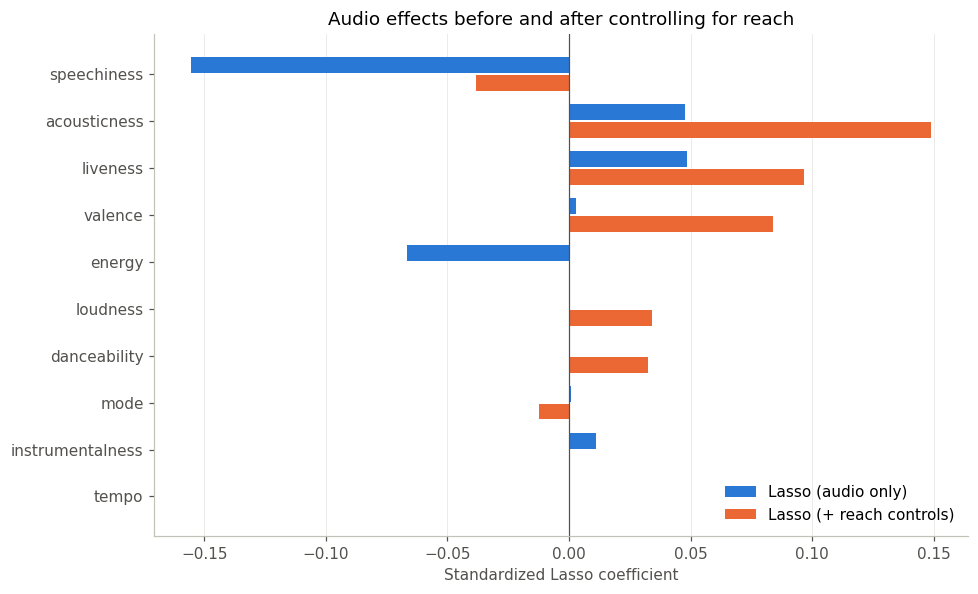

In [17]:
comparison = pd.DataFrame({
    "Lasso (audio only)": coefs["Lasso"],
    "Lasso (+ reach controls)": coefs_ctrl.loc[FEATURES, "Lasso"],
}).reindex(FEATURES)
comparison = comparison.reindex(comparison.abs().max(axis=1).sort_values().index)

yy = np.arange(len(comparison))
h = 0.38
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(yy + h / 2, comparison.iloc[:, 0], height=h - 0.04, color=BLUE, label=comparison.columns[0])
ax.barh(yy - h / 2, comparison.iloc[:, 1], height=h - 0.04, color=ORANGE, label=comparison.columns[1])
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_yticks(yy, comparison.index)
ax.set(xlabel="Standardized Lasso coefficient", title="Audio effects before and after controlling for reach")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()

perf_ctrl = pd.DataFrame({
    name: {
        "R2 (in-sample)": m.score(X_ctrl, y),
        "R2 (5-fold CV)": cross_val_score(m, X_ctrl, y, cv=cv, scoring="r2").mean(),
        "non-zero coefs": int((np.abs(m[-1].coef_) > 1e-4).sum()),
    }
    for name, m in models_ctrl.items()
}).T
perf_ctrl.round(4)

## 8. Conclusions (data from 2026-10-12)

**1. Is there a linear relationship between the audio features and popularity? Yes, but it is weak.**
- With audio features only, the OLS F-test is significant (p ≈ 4·10⁻⁷).
- Those features only explain **R² ≈ 5.7 %** of the variance, or **≈ 3.4 %** on held-out data (5-fold CV).
- No single feature has |r| above 0.19, and Spearman's ρ is close to Pearson's *r*. So the relationships are not strongly non-linear either; there just isn't much signal.

**2. The features are not strongly linearly related to each other.**
- The largest correlations are energy-loudness (r ≈ 0.59) and energy-acousticness (r ≈ -0.43).
- All VIFs are ≤ 2.1, far below 5 or 10.
- That is why **Ridge barely changes anything**: its coefficients are a shrunken copy of OLS, with the same signs and ranking and the same CV R². Regularization has no collinearity problem to fix here.
- There is still a small collinearity effect: loudness has a *negative* simple correlation with streams, but a *positive* OLS coefficient once energy is in the model.

**3. Lasso drops the features with no linear signal.**
- With audio features only, it sets **danceability, loudness and tempo** to exactly 0. It shrinks valence and mode to almost 0.
- With reach controls, it drops **energy, instrumentalness and tempo**.
- Tempo is dropped in both cases, which fits the idea that tempo has no linear relationship with popularity.
- Lasso's CV R² is about the same as OLS's. The value of Lasso here is a **simpler model**, not better predictions.

**4. The most important finding: popularity is mostly about reach, not sound.**
- Our y adds up streams across countries. Whether a song is in the **US chart** and **how many countries** it charts in explain **53 %** of the variance on their own.
- The audio features add only **≈ 5.8 points of R²** on top of that (from 0.530 to 0.588).
- Without these controls, the audio coefficients are **confounded**:

| Feature | Audio only | + reach controls |
|---|---|---|
| speechiness | strongest effect (−0.16) | much weaker (−0.04) |
| energy | −0.07 | dropped by Lasso |
| acousticness | +0.05 | **strongest audio effect (+0.15)** |
| liveness | +0.05 | +0.10 |
| valence | ≈ 0 | +0.08 |

- Speechy and high-energy songs (e.g. rap, reggaeton) tend to be *local* hits, so their apparent negative effect was mostly a market effect.

**Interpretation of the controlled Lasso model.** These are standardized coefficients on log(streams), comparing songs with the same reach:
- **Acousticness:** +1 SD → about **+16 % daily streams** (e^0.149 ≈ 1.16).
- **Liveness:** +1 SD → about +10 %.
- **Valence:** +1 SD → about +9 %, so happier songs do a bit better.
- **Speechiness:** +1 SD → about −4 %.

**Caveats and next steps**
- **Which variables Lasso keeps depends on the CV split.** With a different random seed it kept a slightly different set. Bootstrapping the Lasso (B = 2000) would show how often each variable is selected and give confidence intervals for the coefficients.
- **This is one day of data, and only from songs that are already hits.**
- **About 46 % of chart songs have no audio features** and are not in the sample.